# 5. Target anyon-Hubbard model and energy gaps

**Author:** Aditya Banerjee  
**Thesis:** *Linear Anyon Model with Rydberg Atoms*, Universitat de Barcelona, 2026

The thesis maps the anyon-Hubbard model to bosons with density-dependent hopping. This notebook follows the uploaded matrix-free exact-diagonalization code and then loads the saved ten-site gap maps. The target model is imposed independently of the Rydberg implementation.

**Thesis source:** Sections 1.2–1.3, Eqs. (5)–(8), Appendix C. Descriptions below are adapted from these sections;
equation numbers refer to the thesis. **Code source:** [`sweepGapsMulti.py`](../scripts/sweepGapsMulti.py), [`doApplyHam.py`](../scripts/doApplyHam.py), [`replotGapsMulti.py`](../scripts/replotGapsMulti.py).

**Steps:** local operators → hopping term → Hamiltonian action → low energies → saved grid → gap maps.

Run the numbered sections from top to bottom. Longer derivations and implementation
comparisons are at the end. These are theoretical calculations, not experimental data.

## 1. Import libraries

In [1]:
%matplotlib inline
from pathlib import Path
from itertools import product
import numpy as np
from scipy.special import jv
import matplotlib.pyplot as plt
from IPython.display import display

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
# Run from the repository root or from notebooks/.
here = Path.cwd().resolve()
ROOT = next(p for p in [here, *here.parents] if (p / "scripts").is_dir() and (p / "data").is_dir())
DATA = ROOT / "data"
SAVE_FIGURES = False
STYLE = {"font.size": 11}


def show_figure(fig, name):
    if SAVE_FIGURES:
        destination = ROOT / "notebook_outputs"
        destination.mkdir(exist_ok=True)
        fig.savefig(destination / f"{name}.png", dpi=160)
    display(fig)
    plt.close(fig)

In [3]:
from scipy.sparse.linalg import LinearOperator, eigsh

## 2. Set the model and numerical controls

For open boundaries the thesis gives [Eq. (6)]
$$H=-J\sum_{j=0}^{L-2}\left[b_j^\dagger e^{i\phi n_j}b_{j+1}+\mathrm{h.c.}\right]
+\frac U2\sum_{j=0}^{L-1}n_j(n_j-1).$$
$J$ is the hopping energy, $U>0$ the reference interaction energy, and $\phi$ the
dimensionless statistical angle (`theta` in the source). We solve for $K=H/U$,
so every returned eigenvalue is $E/U$. The source sweep acts in the full $3^L$
space, without a fixed particle number or a chemical-potential term.
**Notebook adaptation:** the live example uses four sites; the saved maps use ten.

In [4]:
Nsites = 4
usePBC = False
numval = 5
U = 1.0
ncv, tol = 40, 1e-8
J, theta = 0.3, np.pi / 2

## 3. Define the local occupation operators

Thesis Eq. (7) truncates the local space to $|0\rangle,|1\rangle,|2\rangle$:
$$b=|0\rangle\langle1|+\sqrt2|1\rangle\langle2|,\qquad n=b^\dagger b.$$
These operators are dimensionless. The truncated commutator is
$[b,b^\dagger]=\operatorname{diag}(1,1,-2)$, not the unbounded bosonic identity.

In [5]:
d = 3
b = np.diag(np.sqrt(np.arange(1, d)), k=1)
bdag = b.conj().T
n_op = bdag @ b
print("b =\n", b)
print("n =\n", n_op)

b =
 [[0.       1.       0.      ]
 [0.       0.       1.414214]
 [0.       0.       0.      ]]
n =
 [[0. 0. 0.]
 [0. 1. 0.]
 [0. 0. 2.]]


## 4. Build the on-site interaction diagonal

Since $\tfrac12n(n-1)$ is zero for $n=0,1$ and one for $n=2$,
each doublon costs $U$. The Kronecker products add that cost at every site.

In [6]:
u_site = (U / 2) * np.arange(d) * (np.arange(d) - 1)
Udiag = np.zeros(d**Nsites)
for k in range(Nsites):
    Udiag += np.kron(np.ones(d**k), np.kron(u_site, np.ones(d ** (Nsites - 1 - k))))

## 5. Apply nearest-neighbour hopping to a state

The source contracts each two-site operator with a reshaped state, avoiding a dense $3^L	imes3^L$ matrix. The leftmost site is the most significant tensor index. The original routine credits Glen Evenbly / tensors.net (v1.2, June 2019).

In [7]:
# doApplyHam.py
# ---------------------------------------------------------------------
# Routine used in the implementation of exact diagonalization.
#
# Adapted from Glen Evenbly (c) for www.tensors.net, (v1.2) - last
# modified 6/2019. Modified for complex Hamiltonians (the anyon-Hubbard
# density-dependent hopping phase e^{i*theta*n_j} makes hloc complex
# Hermitian), and works for arbitrary local dimension d.

def doApplyHam(psiIn: np.ndarray,
               hloc: np.ndarray,
               N: int,
               usePBC: bool):
  """
  Applies local Hamiltonian, given as sum of nearest neighbor terms, to
  an input quantum state.
  Args:
    psiIn: vector of length d**N describing the quantum state.
    hloc: array of ndim=4 describing the nearest neighbor coupling.
    N: the number of lattice sites.
    usePBC: sets whether to include periodic boundary term.
  Returns:
    np.ndarray: state psi after application of the Hamiltonian.
  """
  d = hloc.shape[0]
  psiOut = np.zeros(psiIn.size, dtype=np.result_type(psiIn, hloc))
  for k in range(N - 1):
    # apply local Hamiltonian terms to sites [k,k+1]
    psiOut += np.tensordot(hloc.reshape(d**2, d**2),
                           psiIn.reshape(d**k, d**2, d**(N - 2 - k)),
                           axes=[[1], [1]]).transpose(1, 0, 2).reshape(d**N)

  if usePBC:
    # apply periodic term
    psiOut += np.tensordot(hloc.reshape(d, d, d, d),
                           psiIn.reshape(d, d**(N - 2), d),
                           axes=[[2, 3], [2, 0]]
                           ).transpose(1, 2, 0).reshape(d**N)

  return psiOut

## 6. Calculate the lowest energies

Operator order matters. Acting from right to left gives
$$b_j^\dagger e^{i\phi n_j}b_{j+1}|n,m\rangle
=\sqrt{(n+1)m}\,e^{i\phi n}|n+1,m-1\rangle.$$
The source therefore uses `bdag @ phase`, not `phase @ bdag`.
`eigsh` requests the smallest algebraic eigenvalues; the starting vector is fixed for reproducibility.

In [8]:
def lowest_levels(J, theta):
    """Lowest 'numval' eigenvalues of H(J, U, theta) via Lanczos."""
    phase = np.diag(np.exp(1j * theta * np.diag(n_op)))
    hloc = (-J * (np.kron(bdag @ phase, b) + np.kron(phase.conj().T @ b, bdag))).reshape(d, d, d, d)
    H = LinearOperator(
        (d**Nsites, d**Nsites),
        matvec=lambda v: doApplyHam(v, hloc, Nsites, usePBC) + Udiag * v,
        dtype=np.complex128,
    )
    # fixed starting vector so the sweep is reproducible run to run
    v0 = np.random.default_rng(1234).standard_normal(d**Nsites)
    return np.sort(
        eigsh(H, k=numval, which="SA", return_eigenvectors=False, ncv=ncv, tol=tol, v0=v0)
    )

In [9]:
levels = lowest_levels(J, theta)
print("Four-site levels E/U:", levels / U)
print("Ground-referenced spacings:", (levels[1:] - levels[0]) / U)

Four-site levels E/U: [-0.842781 -0.776679 -0.75746  -0.620428 -0.48541 ]
Ground-referenced spacings: [0.066101 0.085321 0.222352 0.35737 ]


## 7. Load the saved ten-site grid

The saved array is indexed by hopping ratio, angle, and level. It holds five full-space levels at each of the $21	imes21$ grid points; this cell does not rerun that sweep.

In [10]:
with np.load(DATA / "anyonHubbardGapsMulti_N10.npz", allow_pickle=False) as saved:
    ratios, thetas = saved["ratios"].copy(), saved["thetas"].copy()
    energies, saved_U = saved["energies"].copy(), float(saved["U"])
    saved_L, saved_pbc = int(saved["Nsites"]), bool(saved["usePBC"])
print("Saved sites:", saved_L, "array shape:", energies.shape)

Saved sites: 10 array shape: (21, 21, 5)


## 8. Define a gap-map plotting cell

Following `replotGapsMulti.py`, calculate either
$(E_k-E_0)/U$ or $(E_{k+1}-E_k)/U$. Each panel has its own labelled colour scale.
**Plot adaptation:** nearest-cell shading shows the computed grid without interpolating unsampled values.

In [11]:
def plot_gap(difference, label):
    fig, ax = plt.subplots(figsize=(6.5, 4), layout="constrained")
    mesh = ax.pcolormesh(ratios, thetas, difference.T / saved_U, shading="nearest", cmap="cividis")
    fig.colorbar(mesh, ax=ax, label=f"({label})/U")
    ax.set(
        xlabel="J/U",
        ylabel=r"Statistical angle $\phi$ (rad)",
        title=f"{label}; L={saved_L}, open boundaries",
    )
    show_figure(fig, f'05_{label.replace(" ", "")}')

## 9. Plot spacings measured from the ground state

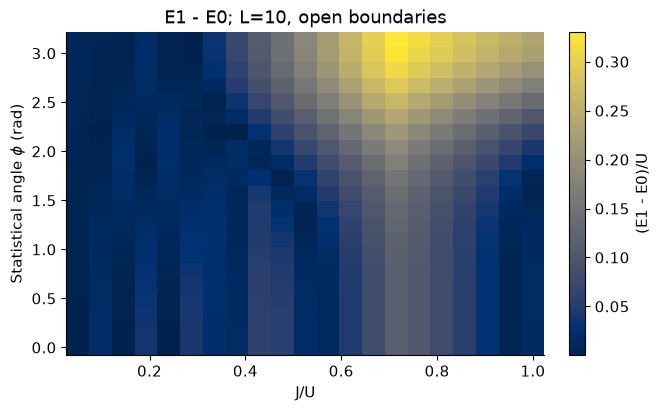

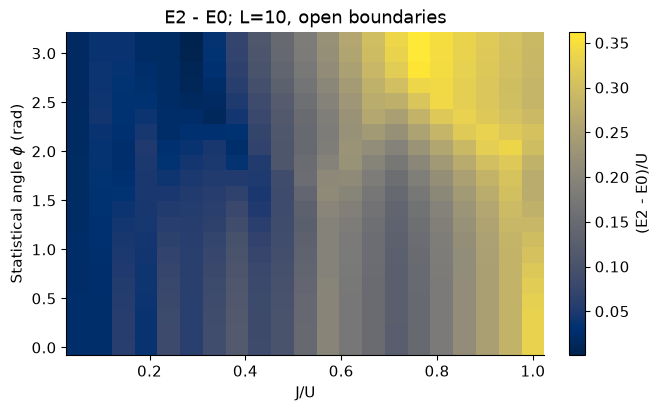

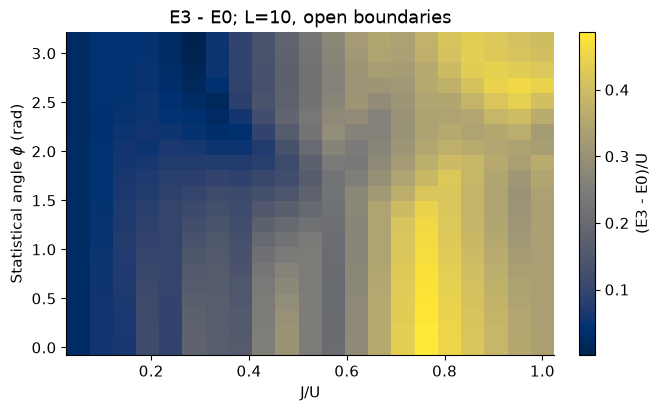

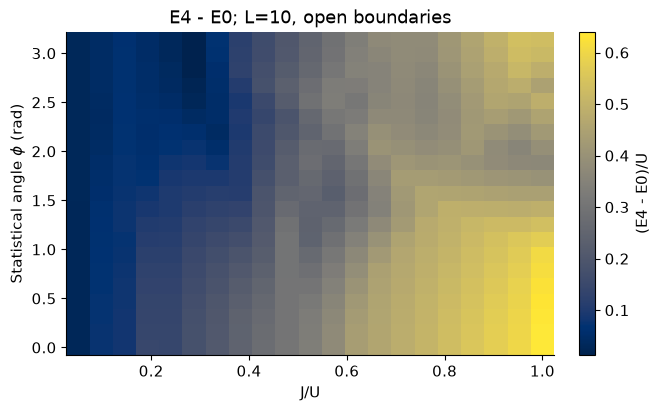

In [12]:
for k in range(1, energies.shape[-1]):
    plot_gap(energies[:, :, k] - energies[:, :, 0], f"E{k} - E0")

## 10. Plot consecutive excited-level spacings

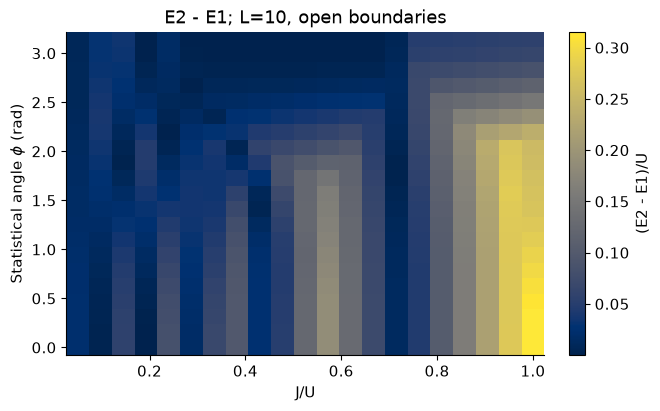

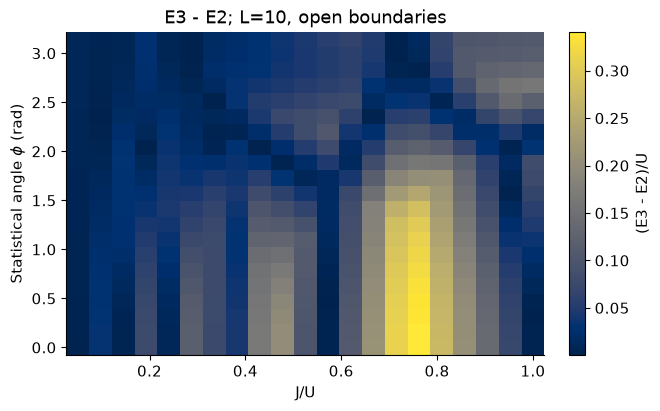

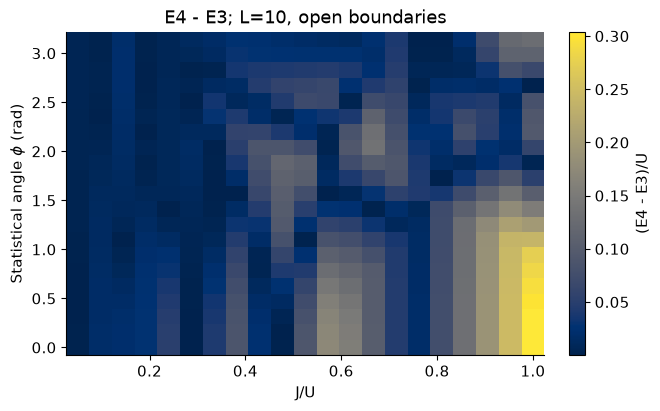

In [13]:
for k in range(1, energies.shape[-1] - 1):
    plot_gap(energies[:, :, k + 1] - energies[:, :, k], f"E{k+1} - E{k}")

## 11. Read the gaps and check the operator

These maps show full-space level spacings. Their two levels may have different $N$.
A fixed-number excitation is $E_1(N)-E_0(N)$; the charge gap is
$E_0(N+1)+E_0(N-1)-2E_0(N)$. These are different quantities.
At $J=0$ only the on-site diagonal remains, and at $\phi=0$ the hopping is real.
Neither a small finite-chain spacing nor a colour-map feature proves a thermodynamic phase transition.

In [14]:
phase = np.diag(np.exp(1j * theta * np.diag(n_op)))
hloc = (-J * (np.kron(bdag @ phase, b) + np.kron(phase.conj().T @ b, bdag))).reshape(d, d, d, d)
flat = hloc.reshape(d * d, d * d)
np.testing.assert_allclose(flat, flat.conj().T, atol=1e-13)
np.testing.assert_allclose(
    np.diag(np.exp(1j * (theta + 2 * np.pi) * np.diag(n_op))), phase, atol=1e-13
)
assert np.all(np.diff(energies, axis=-1) >= -1e-10)
print("Hermitian local hopping, 2-pi periodicity, and saved level ordering: PASS")

Hermitian local hopping, 2-pi periodicity, and saved level ordering: PASS


## Appendix — detailed derivations and verification

The main calculation is complete. This appendix retains the symbolic steps, conventions, limiting cases, and source comparisons for closer study.

### Conventions, dimensions, and evidence status

**Theoretical model:** each site has the orthonormal occupation basis
$|0\rangle,|1\rangle,|2\rangle$. The tensor-product basis is lexicographic,
with the leftmost site the most significant index. Occupations above two are
excluded. State vectors have norm one; probabilities and occupation numbers
are dimensionless. Chains use open boundaries unless explicitly stated.
This is a nonrelativistic finite-dimensional calculation; no spacetime metric
signature is used. Finite sums replace spatial integration, and no continuum
boundary conditions are assumed.

Start with physical energy $H$ and positive reference angular frequency
$\omega_{\rm ref}$. Define
$$K=\frac{H}{\hbar\omega_{\rm ref}},\qquad
  \tau=\omega_{\rm ref}t,\qquad \hbar=\frac{h}{2\pi}.$$
Since $[H]={\rm J}$ and $[\hbar\omega_{\rm ref}]={\rm J\,s}\,{\rm s}^{-1}
={\rm J}$, $K$ is dimensionless. Likewise $[\tau]={\rm s}^{-1}{\rm s}=1$.
Schrödinger evolution becomes
$$i\hbar\,\omega_{\rm ref}\frac{d\psi}{d\tau}
   =\hbar\omega_{\rm ref}K\psi,
  \qquad i\frac{d\psi}{d\tau}=K\psi.$$

**Unresolved source convention:** archived scripts label numerical rates as
MHz while using the numerical matrix in $\exp(-iEt)$; a header also equates MHz with rad/us.
Appendix B of the thesis writes $\omega'/2\pi$ in MHz. If a matrix is supplied
as $H/h$ in cycles per unit time, its propagator is $\exp[-i2\pi(H/h)t]$;
if supplied as $H/\hbar$, it is $\exp[-i(H/\hbar)t]$. Dimensional analysis
cannot distinguish these two conventions. The notebooks therefore preserve
native numerical values and use $\tau$, without claiming a calibrated
microsecond axis. Any physical conversion requires a declared convention.
For the effective-model numerical cells, the reference is one native rate
unit: a rate divided by that reference has the same numerical value.
Thus the arrays used in the propagator are dimensionless $K$, even when
the source-formula coefficients are described below as native rates.

**Source-backed numerical facts** refer to the archived files and checks
shown here. They are not experimental observations. **Physical reachability**
and **proposed extensions** are labelled separately. See
[scientific notes](../SCIENTIFIC_NOTES.md) for unresolved interpretations.

### 5.1 Local operators, truncation, and operator ordering

In the ordered local basis the truncated bosonic lowering operator is
$$b=\begin{pmatrix}0&1&0\\0&0&\sqrt2\\0&0&0\end{pmatrix},\qquad
  n=b^\dagger b=\operatorname{diag}(0,1,2).$$
It obeys $b|n\rangle=\sqrt n\,|n-1\rangle$ and $b^\dagger|2\rangle=0$.
At the cutoff the usual infinite-dimensional commutator is modified:
$$bb^\dagger=\operatorname{diag}(1,2,0),\quad
  [b,b^\dagger]=\operatorname{diag}(1,1,-2)=I-3|2\rangle\langle2|.$$
The truncation is an explicit model assumption, not an exact representation
of unbounded bosonic occupation.

For an open chain use
$$H=-J\sum_{j=0}^{L-2}\left[b_j^\dagger e^{i\theta n_j}b_{j+1}
  +b_{j+1}^\dagger e^{-i\theta n_j}b_j\right]
  +\frac U2\sum_{j=0}^{L-1}n_j(n_j-1).$$
$J$ and $U$ have energy units, $\theta$ is dimensionless, and both brackets
contain dimensionless operators. The two hopping terms are conjugate
transposes with their order reversed, ensuring Hermiticity.

Act on a bond $|n,m\rangle$ **from right to left**:
$$b_{j+1}|n,m\rangle=\sqrt m\,|n,m-1\rangle,$$
$$e^{i\theta n_j}\sqrt m\,|n,m-1\rangle
   =\sqrt m e^{i\theta n}|n,m-1\rangle,$$
$$b_j^\dagger\sqrt m e^{i\theta n}|n,m-1\rangle
   =\sqrt{(n+1)m}\,e^{i\theta n}|n+1,m-1\rangle.$$
Multiplication by $-J$ gives the implemented matrix element. The reverse
amplitude is its complex conjugate. The four forward processes therefore
have factors $1,\sqrt2,\sqrt2,2$ and phases $0,\theta,0,\theta$.
Their total particle number is unchanged.

Choose a positive reference interaction $U$ and divide by it:
$$K=H/U,\qquad K=-(J/U)\sum_j(\text{hopping}+\text{h.c.})
    +\frac12\sum_jn_j(n_j-1).$$
Eigenvalues of $K$ are $E/U$. This reference $U$ is distinct from the
potentially negative $U_{\rm eff}$ in Notebook 4.

### 5.2 Full-space and fixed-number gaps answer different questions

Write the ordered eigenvalues in sector $N$ as $E_0(N),E_1(N),\ldots$.
A fixed-number excitation is
$$\Delta_N=E_1(N)-E_0(N).$$
If all sectors are combined and ordered, their lowest levels are
$E_0^{\rm all}\leq E_1^{\rm all}\leq\cdots$, giving
$$\Delta_{\rm all}=E_1^{\rm all}-E_0^{\rm all}.$$
The two levels in the latter expression may have different particle numbers.
Neither expression is automatically the charge gap
$E_0(N+1)+E_0(N-1)-2E_0(N)$. State which quantity is computed.

A sparse solver seeks only a few eigenpairs. For a returned normalized
eigenvector $v$, compute the residual $\|Kv-\lambda v\|$; small residuals
test the eigenproblem solution, not the physical model. Degenerate levels
and finite size require care when interpreting small gaps.

### 5.5 Limiting cases and independent numerical checks

At $J=0$, $K=\tfrac12\sum_jn_j(n_j-1)$ is diagonal: a doublon costs one,
and occupations zero or one cost zero. At $\theta=0$, the hopping reduces
to the real truncated Bose-Hubbard hopping. At $\theta+2\pi$, each integer
occupation gives the same phase as at $\theta$, so the matrix repeats.
At $\theta=\pi$, the phase is $(-1)^{n_j}$; because double occupation remains
allowed, this is not the same local Hilbert space as spinless fermions.

The automated tests additionally compare this Fock-space assembly with the
original tensor-contraction operator, for open and periodic chains. That is
an independent implementation check of operator ordering and boundary terms.

### Compare the notebook calculation with the validated reference

The following cell is an implementation check. The main calculation above contains its own code and does not require these reference imports.

In [15]:
import sys

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from anyon_thesis.models import target_hamiltonian

reference_H, basis = target_hamiltonian(Nsites, J, U, theta)
eye = np.eye(d**Nsites)
visible_H = np.column_stack([doApplyHam(v, hloc, Nsites, usePBC) + Udiag * v for v in eye.T])
np.testing.assert_allclose(visible_H, reference_H.toarray(), atol=1e-13)
np.testing.assert_allclose(levels, np.linalg.eigvalsh(visible_H)[:numval], atol=1e-8)
print("Original matrix-free operator and low-energy solve match the dense reference: PASS")

Original matrix-free operator and low-energy solve match the dense reference: PASS


### Sources and adaptations

- [Read the thesis](https://hdl.handle.net/2445/231684); thesis equation numbers are identified beside their use.
- Original calculation code: [`sweepGapsMulti.py`](../scripts/sweepGapsMulti.py), [`doApplyHam.py`](../scripts/doApplyHam.py), [`replotGapsMulti.py`](../scripts/replotGapsMulti.py), source commit `22959963191fcbc4d283ec4b272b506ad6dd979b`.
- [Scientific notes](../SCIENTIFIC_NOTES.md): frequency convention, imposed compensation, physical phase reachability, and finite-size interpretation.
- [Validation and adaptation record](VALIDATION.md).
- Notebook layout follows the short, numbered explanation–code–output pattern of the
  [AQI example](https://github.com/Charub17/global-air-pollution-aqi-ml/blob/main/Global_Air_Pollution_AQI_ML.ipynb).
  Its prose, data analysis, and numerical claims are not reused.

The code cells retain the source calculations. Notebook-specific adaptations are
labelled beside the relevant cell. No large archived job is launched implicitly.